# 01 · Data Collection
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `01_data_collection.ipynb` |
| **Term paper part** | (b) Mine the appropriate dataset |

### Objective
Obtain the Kenyan Sign Language image dataset, store a permanent copy on Google Drive, check that every image is present and readable, and build a clean **catalogue** (one row per image) that all later notebooks use.

### Inputs
- Kaggle dataset `awsaf49/kslc-dataset` (downloaded with the Kaggle API)
- Kaggle API token stored in Colab Secrets as `KAGGLE_API_TOKEN`

### Outputs
| File | Location | Purpose |
|---|---|---|
| `kslc_dataset.zip` | `data/raw/` | Permanent backup of the raw dataset |
| `catalogue_labelled.csv` | `data/processed/` | One row per labelled image: ID, label, path, size, readable |
| `catalogue_unlabelled.csv` | `data/processed/` | Same for the unlabelled competition test images |
| `01_raw_files.csv`, `01_class_counts.csv`, `01_image_dimensions.csv` | `outputs/tables/` | Tables for the report |
| `01_sample_grid.png` | `outputs/figures/` | One example image per sign (for the presentation) |
| Key numbers | `outputs/results.json` | Image counts, classes, missing/corrupt files |

### About the dataset

| | |
|---|---|
| **Original source** | Kenyan Sign Language Classification Challenge, hosted on Zindi Africa |
| **Accessed via** | Kaggle re-upload *KSLC Dataset* by user `awsaf49` (Zindi no longer allows downloads) |
| **Content** | Photographs of people performing 9 KSL signs |
| **Classes** | Church, Enough/Satisfied, Friend, Love, Me, Mosque, Seat, Temple, You |
| **Size** | 1.19 GB, 8,931 files |
| **Licence** | Not stated on Kaggle; both Zindi and the Kaggle uploader are credited as sources in the report |

The download contains `train.csv` (images **with** labels), `test.csv` (competition test images **without** labels) and `sample_submission.csv`. Only labelled images can be used to train and evaluate models, so the labelled set is our working dataset; we will make our own train/validation/test split from it in a later notebook.

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
# 1. Connect Google Drive (where the data, models and outputs live)
from google.colab import drive
drive.mount("/content/drive")

# 2. Make the shared helper file (ksl_utils.py) importable
import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

# 3. Import helpers and fix the random seed for reproducibility
import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

# 4. Name of THIS notebook: every saved figure/table/result is tagged with it
NOTEBOOK = "01_data_collection"

# 5. Shortcuts to the project folders
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


In [2]:
# Libraries used in this notebook
import os
import time
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm   # progress bars for long loops

## 1 · Connect to Kaggle
`kagglehub` is Kaggle's official Python library for downloading datasets. It reads the API token from the environment variable `KAGGLE_API_TOKEN`, so we load the token from **Colab Secrets** (🔑 icon in the left sidebar) instead of typing it into the notebook, which keeps it out of GitHub.

In [3]:
# Install / upgrade kagglehub (version 0.4.1+ supports the new Kaggle API tokens)
!pip install -q "kagglehub>=0.4.1"

In [4]:
# Read the token from Colab Secrets and expose it to kagglehub
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("Kaggle token loaded:", "yes" if os.environ["KAGGLE_API_TOKEN"] else "no")

Kaggle token loaded: yes


## 2 · Download the dataset
`kagglehub.dataset_download` downloads and unzips the dataset onto Colab's local disk. Local disk is fast but is **wiped when the session ends**, so in Step 3 we keep a permanent copy on Drive.

In [5]:
# Download the dataset from Kaggle (about 1.2 GB; usually under 2 minutes)
import kagglehub

start = time.time()
DOWNLOAD_DIR = Path(kagglehub.dataset_download("awsaf49/kslc-dataset"))
print(f"Downloaded to: {DOWNLOAD_DIR}")
print(f"Time taken   : {time.time() - start:.0f} s")

100%|██████████| 1.10G/1.10G [00:17<00:00, 68.9MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/awsaf49/kslc-dataset/versions/1
Time taken   : 35 s


### 2.1 · What was downloaded
List the top-level files and folders with their sizes and file counts.

In [6]:
def folder_stats(path: Path):
    """Return (number of files, total size in MB) for a file or a folder."""
    if path.is_file():
        return 1, path.stat().st_size / 1e6
    files = [p for p in path.rglob("*") if p.is_file()]
    return len(files), sum(p.stat().st_size for p in files) / 1e6

# One row per top-level item in the download
rows = []
for item in sorted(DOWNLOAD_DIR.iterdir()):
    n_files, size_mb = folder_stats(item)
    rows.append({"item": item.name,
                 "type": "folder" if item.is_dir() else "file",
                 "files": n_files,
                 "size_mb": round(size_mb, 2)})
raw_files = pd.DataFrame(rows)

# Save for the report and log the totals
ku.save_table(raw_files, "01_raw_files", NOTEBOOK, caption="Contents of the downloaded KSLC dataset.")
ku.log_result("raw_total_files", int(raw_files["files"].sum()), NOTEBOOK)
ku.log_result("raw_total_size_mb", round(float(raw_files["size_mb"].sum()), 1), NOTEBOOK)
raw_files

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/01_raw_files.csv
Result logged: raw_total_files = 8931
Result logged: raw_total_size_mb = 1185.7


,item,type,files,size_mb
0,Images,folder,8928,1185.39
1,sample_submission.csv,file,1,0.07
2,test.csv,file,1,0.05
3,train.csv,file,1,0.15


**Interpretation:** the download has **8,931 files (1,185.7 MB)**, matching the Kaggle page exactly: 8,928 images in `Images/` plus three CSV files. The download is complete.

## 3 · Keep a permanent copy on Google Drive
We save the whole dataset as **one zip file** in `data/raw/`. One large file copies to and from Drive far faster than thousands of small images, and it means the project no longer depends on the Kaggle upload staying online.

Images are already compressed (JPEG), so the zip uses no extra compression (`ZIP_STORED`), which makes it quick to build. This step is skipped if the backup already exists.

In [7]:
if os.path.exists(ku.RAW_ZIP):
    print(f"Backup already exists: {ku.RAW_ZIP} ({os.path.getsize(ku.RAW_ZIP)/1e9:.2f} GB), skipping.")
else:
    start = time.time()
    tmp_zip = "/content/kslc_dataset.zip"           # build on fast local disk first
    all_files = [p for p in DOWNLOAD_DIR.rglob("*") if p.is_file()]
    with zipfile.ZipFile(tmp_zip, "w", compression=zipfile.ZIP_STORED) as z:
        for p in tqdm(all_files, desc="Zipping"):
            z.write(p, arcname=p.relative_to(DOWNLOAD_DIR))   # keep the folder structure
    shutil.copy(tmp_zip, ku.RAW_ZIP)                  # then copy the single file to Drive
    os.remove(tmp_zip)
    print(f"Backup saved to {ku.RAW_ZIP} in {time.time() - start:.0f} s")

Zipping:   0%|          | 0/8931 [00:00<?, ?it/s]

Backup saved to /content/drive/MyDrive/DSA4050/ksl-recognition/data/raw/kslc_dataset.zip in 14 s


### 3.1 · Load the data from the backup
From now on every notebook gets the data with **`ku.restore_raw_data()`**, which unzips the Drive backup onto Colab's local disk (once per session). Using it here too confirms the backup works.

In [8]:
# Unzip the Drive backup to local disk and use that copy from here on
DATA_DIR = Path(ku.restore_raw_data())
print("Working data folder:", DATA_DIR)
print("Contents:", sorted(p.name for p in DATA_DIR.iterdir()))

Data restored to /content/ksl_data in 11s
Working data folder: /content/ksl_data
Contents: ['Images', 'sample_submission.csv', 'test.csv', 'train.csv']


## 4 · Read the label files

In [9]:
# Load the three CSV files that come with the dataset
train_csv = pd.read_csv(DATA_DIR / "train.csv")              # labelled images
test_csv = pd.read_csv(DATA_DIR / "test.csv")                # unlabelled competition images
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv") # competition answer template

for name, df in [("train.csv", train_csv), ("test.csv", test_csv), ("sample_submission.csv", sample_sub)]:
    print(f"{name:<22} rows = {len(df):>5}   columns = {list(df.columns)}")

train_csv.head()

train.csv              rows =  6249   columns = ['img_IDS', 'Label']
test.csv               rows =  2679   columns = ['img_IDS']
sample_submission.csv  rows =  2679   columns = ['img_IDS', 'Church', 'Enough/Satisfied', 'Friend', 'Love', 'Me', 'Mosque', 'Seat', 'Temple', 'You']


,img_IDS,Label
0,ImageID_33HMDMJ3,Temple
1,ImageID_V5POEX4O,Church
2,ImageID_89CCCCW6,Enough/Satisfied
3,ImageID_GNJXOWX5,Me
4,ImageID_7Q9LOP7R,Love


### 4.1 · Identify the ID and label columns
The column names are detected automatically: the **ID column** is the one whose values look like `ImageID_…`, and the **label column** is the other text column in `train.csv`.

In [10]:
def find_id_column(df: pd.DataFrame) -> str:
    """Return the column whose values look like image IDs (e.g. 'ImageID_USRB8QNG')."""
    for col in df.columns:
        if df[col].astype(str).str.startswith("ImageID").mean() > 0.9:
            return col
    raise ValueError(f"No image-ID column found in {list(df.columns)}")

ID_COL = find_id_column(train_csv)
TEST_ID_COL = find_id_column(test_csv)
# The label column is the remaining text column in train.csv
LABEL_COL = [c for c in train_csv.columns if c != ID_COL and not pd.api.types.is_numeric_dtype(train_csv[c])][0]

print("ID column    :", ID_COL)
print("Label column :", LABEL_COL)
print("Classes      :", sorted(train_csv[LABEL_COL].unique()))

ID column    : img_IDS
Label column : Label
Classes      : ['Church', 'Enough/Satisfied', 'Friend', 'Love', 'Me', 'Mosque', 'Seat', 'Temple', 'You']


## 5 · Match every ID to an image file
We index all image files in the download by their name (without extension), then look up each ID. Any ID without a file is reported as **missing**.

In [11]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

# Map "ImageID_XXXX" -> full path of the image file
image_index = {p.stem: p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS}
print(f"Image files found on disk: {len(image_index)}")
print("Example:", next(iter(image_index.values())))

# Look up each ID; missing ones get NaN
train_csv["path"] = train_csv[ID_COL].map(image_index)
test_csv["path"] = test_csv[TEST_ID_COL].map(image_index)

n_missing_train = int(train_csv["path"].isna().sum())
n_missing_test = int(test_csv["path"].isna().sum())
print(f"Labelled IDs without an image  : {n_missing_train}")
print(f"Unlabelled IDs without an image: {n_missing_test}")

ku.log_result("n_image_files_on_disk", len(image_index), NOTEBOOK)
ku.log_result("n_missing_labelled", n_missing_train, NOTEBOOK)
ku.log_result("n_missing_unlabelled", n_missing_test, NOTEBOOK)

Image files found on disk: 8928
Example: /content/ksl_data/Images/Images/ImageID_VTDJ00WV.jpg
Labelled IDs without an image  : 0
Unlabelled IDs without an image: 0
Result logged: n_image_files_on_disk = 8928
Result logged: n_missing_labelled = 0
Result logged: n_missing_unlabelled = 0


## 6 · Integrity check and image catalogue
Each image is opened to confirm it is a valid, readable file, and its width, height, colour mode and file size are recorded. This **catalogue** is what later notebooks read instead of searching the folders again.

Paths are stored **relative to the data folder**, so the catalogue still works in a new session after `ku.restore_raw_data()`.

In [12]:
def inspect_image(path) -> dict:
    """Open one image and return its properties; mark it unreadable if anything fails."""
    info = {"readable": False, "width": np.nan, "height": np.nan, "mode": None, "file_kb": np.nan}
    if pd.isna(path):
        return info
    try:
        info["file_kb"] = round(os.path.getsize(path) / 1024, 1)
        with Image.open(path) as img:
            img.verify()                     # checks the file is not corrupt
        with Image.open(path) as img:        # re-open: verify() leaves the image unusable
            info["width"], info["height"] = img.size
            info["mode"] = img.mode          # e.g. RGB = colour, L = greyscale
        info["readable"] = True
    except Exception:
        pass
    return info


def build_catalogue(df: pd.DataFrame, id_col: str, label_col=None) -> pd.DataFrame:
    """One row per image: id, label (if any), relative path and image properties."""
    records = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Checking images"):
        rec = {"image_id": row[id_col],
               "label": row[label_col] if label_col else None,
               "rel_path": str(Path(row["path"]).relative_to(DATA_DIR)) if pd.notna(row["path"]) else None}
        rec.update(inspect_image(row["path"]))
        records.append(rec)
    return pd.DataFrame(records)


catalogue = build_catalogue(train_csv, ID_COL, LABEL_COL)
catalogue_unlab = build_catalogue(test_csv, TEST_ID_COL)

# Save both catalogues to Drive (data/processed/)
catalogue.to_csv(os.path.join(PATHS["processed"], "catalogue_labelled.csv"), index=False)
catalogue_unlab.to_csv(os.path.join(PATHS["processed"], "catalogue_unlabelled.csv"), index=False)
print("Catalogues saved to", PATHS["processed"])
catalogue.head()

Checking images:   0%|          | 0/6249 [00:00<?, ?it/s]

Checking images:   0%|          | 0/2679 [00:00<?, ?it/s]

Catalogues saved to /content/drive/MyDrive/DSA4050/ksl-recognition/data/processed


,image_id,label,rel_path,readable,width,height,mode,file_kb
0,ImageID_33HMDMJ3,Temple,Images/Images/ImageID_33HMDMJ3.jpg,True,720,1280,RGB,124.8
1,ImageID_V5POEX4O,Church,Images/Images/ImageID_V5POEX4O.jpg,True,720,1280,RGB,84.7
2,ImageID_89CCCCW6,Enough/Satisfied,Images/Images/ImageID_89CCCCW6.jpg,True,1280,720,RGB,119.3
3,ImageID_GNJXOWX5,Me,Images/Images/ImageID_GNJXOWX5.jpg,True,720,1280,RGB,90.1
4,ImageID_7Q9LOP7R,Love,Images/Images/ImageID_7Q9LOP7R.jpg,True,720,1280,RGB,89.9


In [13]:
# Integrity summary: how many images are usable?
n_corrupt = int((~catalogue["readable"]).sum())
usable = catalogue[catalogue["readable"]].copy()

ku.log_result("n_labelled_total", len(catalogue), NOTEBOOK)
ku.log_result("n_labelled_corrupt_or_missing", n_corrupt, NOTEBOOK)
ku.log_result("n_labelled_usable", len(usable), NOTEBOOK)
ku.log_result("n_unlabelled_total", len(catalogue_unlab), NOTEBOOK)

print(f"Labelled images        : {len(catalogue)}")
print(f"  unreadable / missing : {n_corrupt}")
print(f"  usable               : {len(usable)}")
print(f"Unlabelled (not used)  : {len(catalogue_unlab)}")

Result logged: n_labelled_total = 6249
Result logged: n_labelled_corrupt_or_missing = 0
Result logged: n_labelled_usable = 6249
Result logged: n_unlabelled_total = 2679
Labelled images        : 6249
  unreadable / missing : 0
  usable               : 6249
Unlabelled (not used)  : 2679


**Interpretation:** all **6,249 labelled images** have a matching file and open correctly: **0 missing, 0 corrupt**. The 2,679 unlabelled competition images are also complete, but they cannot be used for training or evaluation because their labels were never released.

## 7 · Class counts
How many usable images does each sign have? A large gap between the biggest and smallest class (**class imbalance**) would mean accuracy alone could be misleading, and we would also report macro-F1.

In [14]:
class_counts = (usable["label"].value_counts()
                .rename_axis("sign").reset_index(name="images"))
class_counts["percent"] = (100 * class_counts["images"] / class_counts["images"].sum()).round(1)

# Imbalance ratio = largest class / smallest class (1.0 = perfectly balanced)
imbalance = class_counts["images"].max() / class_counts["images"].min()

ku.save_table(class_counts, "01_class_counts", NOTEBOOK, caption="Number of usable labelled images per KSL sign.")
ku.log_result("n_classes", int(class_counts.shape[0]), NOTEBOOK)
ku.log_result("class_names", sorted(class_counts["sign"].tolist()), NOTEBOOK)
ku.log_result("imbalance_ratio", round(float(imbalance), 2), NOTEBOOK)

print(f"Imbalance ratio (largest / smallest class): {imbalance:.2f}")
class_counts

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/01_class_counts.csv
Result logged: n_classes = 9
Result logged: class_names = ['Church', 'Enough/Satisfied', 'Friend', 'Love', 'Me', 'Mosque', 'Seat', 'Temple', 'You']
Result logged: imbalance_ratio = 1.0
Imbalance ratio (largest / smallest class): 1.00


,sign,images,percent
0,Enough/Satisfied,695,11.1
1,Seat,695,11.1
2,Mosque,695,11.1
3,Temple,694,11.1
4,Church,694,11.1
5,Love,694,11.1
6,Me,694,11.1
7,You,694,11.1
8,Friend,694,11.1


**Interpretation:** the dataset is **perfectly balanced**: every sign has 694 or 695 images (11.1% each, imbalance ratio 1.00). No class weighting or resampling is needed, and accuracy is a fair headline metric (macro-F1 will still be reported alongside it).

## 8 · Image dimensions
Images from a crowd-sourced dataset usually differ in size. Models need one fixed input size, so we record the range here to choose a sensible size later (e.g. 224 × 224 for pretrained CNNs).

In [15]:
dims = usable[["width", "height", "file_kb"]].describe().T.round(1)
dims.index = ["width (px)", "height (px)", "file size (KB)"]

# Most common width x height combination
usable["size"] = usable["width"].astype(int).astype(str) + "x" + usable["height"].astype(int).astype(str)
top_sizes = usable["size"].value_counts().head(5)
modes = usable["mode"].value_counts()

ku.save_table(dims.reset_index(names="measure"), "01_image_dimensions", NOTEBOOK,
              caption="Summary of image width, height and file size.")
ku.log_result("most_common_size", top_sizes.index[0], NOTEBOOK)
ku.log_result("n_distinct_sizes", int(usable["size"].nunique()), NOTEBOOK)
ku.log_result("colour_modes", modes.to_dict(), NOTEBOOK)

print("Most common sizes:\n", top_sizes.to_string())
print("\nColour modes:\n", modes.to_string())
dims

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/01_image_dimensions.csv
Result logged: most_common_size = 720x1280
Result logged: n_distinct_sizes = 2
Result logged: colour_modes = {'RGB': 6249}
Most common sizes:
 size
720x1280    4945
1280x720    1304

Colour modes:
 mode
RGB    6249


,count,mean,std,min,25%,50%,75%,max
width (px),6249.0,836.9,227.6,720.0,720.0,720.0,720.0,1280.0
height (px),6249.0,1163.1,227.6,720.0,1280.0,1280.0,1280.0,1280.0
file size (KB),6249.0,129.7,39.6,48.2,100.6,123.2,152.9,330.9


**Interpretation:** there are only **two image sizes**, the same phone resolution in two orientations: **720×1280 portrait (4,945 images, 79%)** and **1280×720 landscape (1,304 images, 21%)**. All images are colour (RGB). Images will be resized to a square input (e.g. 224×224); the mix of orientations means we must decide between stretching and padding, which we will compare in preprocessing.

## 9 · First look: one example per sign
A grid with one random image per class, saved for the presentation (part b: *present the dataset to the class*).

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/01_sample_grid.png


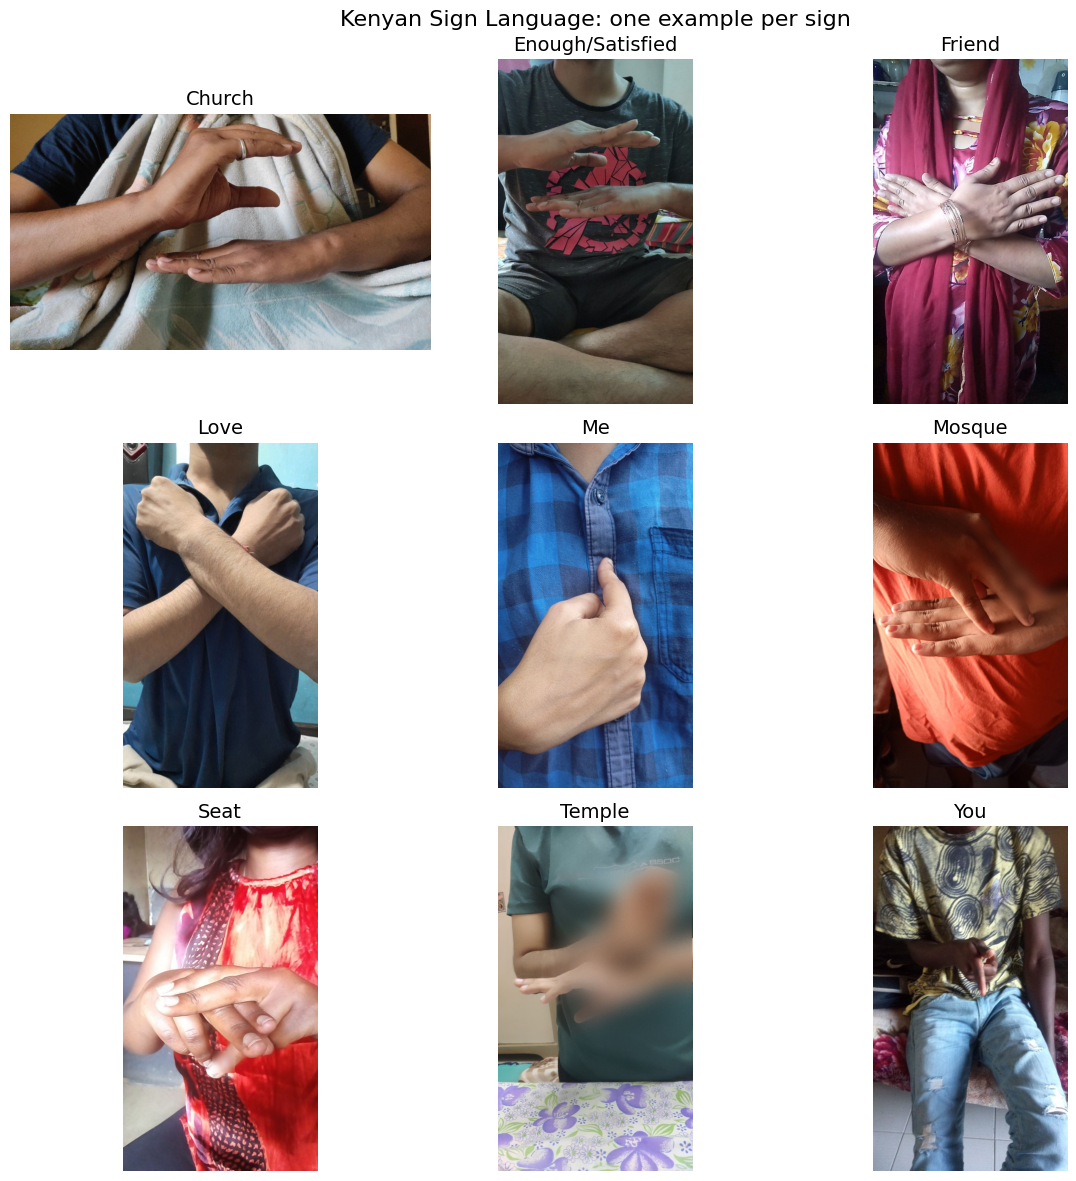

In [16]:
signs = sorted(usable["label"].unique())
n_cols = 3
n_rows = int(np.ceil(len(signs) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
for ax, sign in zip(axes.flat, signs):
    row = usable[usable["label"] == sign].sample(1, random_state=ku.SEED).iloc[0]
    with Image.open(DATA_DIR / row["rel_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(sign, fontsize=14)
    ax.axis("off")
for ax in list(axes.flat)[len(signs):]:   # hide unused panels
    ax.axis("off")

fig.suptitle("Kenyan Sign Language: one example per sign", fontsize=16)
fig.tight_layout()
ku.save_figure(fig, "01_sample_grid", NOTEBOOK, caption="One example image for each of the nine KSL signs.")
plt.show()

**Interpretation:** the photos are **smartphone pictures taken in everyday home settings** by different signers, with varied clothing, skin tones, backgrounds and lighting; faces are mostly out of frame, so the model must rely on hand and arm shape. Some images show **motion blur** (e.g. *Temple*). Several signs look alike, which may cause confusion: *Church*, *Enough/Satisfied* and *Mosque* all use flat horizontal hands, and *Love* and *Friend* both cross the arms over the chest.

## Check · Project status

In [17]:
# Show what has been saved so far
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 1
Tables       : 4
Models       : 0
Results      : 22
Experiments  : 0


## Findings for the report
- **Source:** the Kenyan Sign Language Classification Challenge dataset (Zindi Africa), obtained through the Kaggle re-upload *KSLC Dataset*: 8,931 files, 1.19 GB, 9 signs (Church, Enough/Satisfied, Friend, Love, Me, Mosque, Seat, Temple, You).
- **Usable data:** 6,249 labelled images, all present and readable (0 missing, 0 corrupt). The 2,679 competition test images are unlabelled and excluded; our own train/validation/test split will be drawn from the labelled set.
- **Balance:** perfectly balanced, at 694–695 images per sign (imbalance ratio 1.00).
- **Image format:** all RGB smartphone photos in two orientations: 720×1280 portrait (79%) and 1280×720 landscape (21%). Resizing to a fixed square input is required.
- **Visual variety:** real-world home settings with varied signers, clothing, backgrounds and lighting, plus some motion blur. Visually similar sign pairs (*Church / Enough / Mosque*, *Love / Friend*) are expected to be the hardest to tell apart.

**Next notebook:** `02_eda.ipynb`: deeper exploration (class distribution chart, orientation per sign, brightness and blur, duplicate check, more examples per sign).